# Portuguese Bank Marketing Dataset — Task 1: Complete Data Analysis Report

## 1. Business understanding
The dataset contains records from direct phone-call marketing campaigns conducted by a Portuguese banking institution from May 2008 to November 2010. The campaign promoted term deposits to existing customers.

**Task objective:** perform exploratory data analysis (EDA), understand customer and campaign characteristics, study the target variable (`y`), identify patterns associated with term-deposit subscription, and present actionable findings.

**Dataset required by the project brief:** `Data/bank-additional/bank-additional-full.csv`.

> Important: `duration` is recorded after a call and is not known before calling a customer. The project brief says it should be excluded from a realistic predictive model. In this Task 1 report it is explored descriptively, but it must not be treated as a pre-call predictor in Task 2.


## 2. Import libraries and load data

Place the supplied ZIP file in the same folder as this notebook. The code extracts the specified CSV file from the ZIP archive. Alternatively, set `CSV_PATH` to the extracted CSV location.


In [1]:
import pandas as pd
from pathlib import Path

CSV_PATH = Path(
    r"C:\Users\DELL\Desktop\Portuguese_Bank_Project\PRCP-1000-ProtugeseBank\Data\bank-additional\bank-additional-full.csv"
)

if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH, sep=";")
    print("Dataset loaded successfully!")
    print("Dataset Shape:", df.shape)
else:
    print("Dataset file not found. Please check the file location.")


Dataset loaded successfully!
Dataset Shape: (41188, 21)


## 3. Dataset overview

The dataset contains 41,188 rows and 21 columns. The input fields describe customer demographics, loans, contact details, previous campaign history, and economic indicators. The output variable is `y`, which indicates whether the customer subscribed to a term deposit (`yes` or `no`).


In [2]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
display(df.dtypes.to_frame("data_type"))
print("\\nDataset information:")
df.info()


Rows: 41188
Columns: 21
\nColumn names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
\nData types:


,data_type
age,int64
job,str
marital,str
education,str
default,str
housing,str
loan,str
contact,str
month,str
day_of_week,str


\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   411

## 4. Data quality checks

Check duplicate records, missing values, and the dataset's special `unknown` category. In this dataset, `unknown` is an explicit category in several categorical columns, not a blank/null value. It should be reported separately rather than silently treated as an ordinary missing value.


In [3]:
print("Exact duplicate rows:", df.duplicated().sum())
print("\\nNull values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("null_count"))

unknown_counts = pd.Series({
    col: int(df[col].eq("unknown").sum())
    for col in df.select_dtypes(include="object").columns
}).sort_values(ascending=False)
print("\\n'unknown' category counts:")
display(unknown_counts.to_frame("unknown_count"))
import matplotlib.pyplot as plt


Exact duplicate rows: 12
\nNull values by column:


,null_count
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


\n'unknown' category counts:


C:\Users\DELL\AppData\Local\Temp\ipykernel_17384\1480431418.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns


,unknown_count
default,8597
education,1731
housing,990
loan,990
job,330
marital,80
contact,0
month,0
day_of_week,0
poutcome,0


## 5. Descriptive statistics

Numerical summaries show the central tendency, spread, and range of the numerical variables. Categorical summaries show the number of distinct categories and most frequent category.


In [4]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Target variable analysis

The target `y` is imbalanced: most customers did not subscribe. Accuracy alone would therefore be a misleading metric in a later classification task. The subscription rate is the percentage of records labelled `yes`.


,count,percentage
y,,
no,36548,88.73
yes,4640,11.27


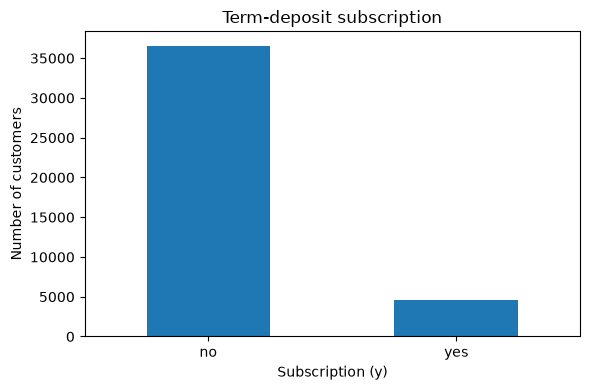

Overall subscription rate: 11.27%


In [5]:
target_counts = df["y"].value_counts()
target_pct = df["y"].value_counts(normalize=True).mul(100)

display(pd.DataFrame({"count": target_counts, "percentage": target_pct.round(2)}))

ax = target_counts.plot(kind="bar", rot=0, figsize=(6,4), title="Term-deposit subscription")
ax.set_xlabel("Subscription (y)")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

print(f"Overall subscription rate: {(df['y'].eq('yes').mean()*100):.2f}%")
import numpy as np


## 7. Numerical feature analysis

The numerical fields are `age`, `duration`, `campaign`, `pdays`, `previous`, and the five economic indicators. Histograms help identify skewness and unusual ranges. Boxplots help reveal extreme values.

**Interpretation caution:** `pdays = 999` is a documented code meaning the customer was not previously contacted in an earlier campaign; it is not an ordinary number of days.


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


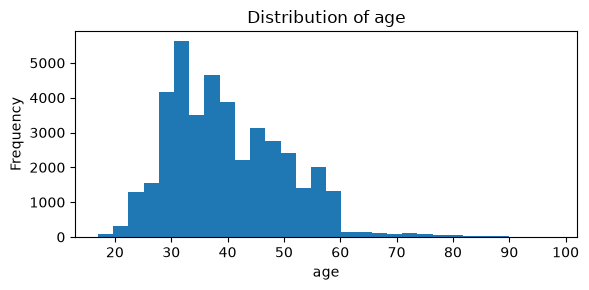

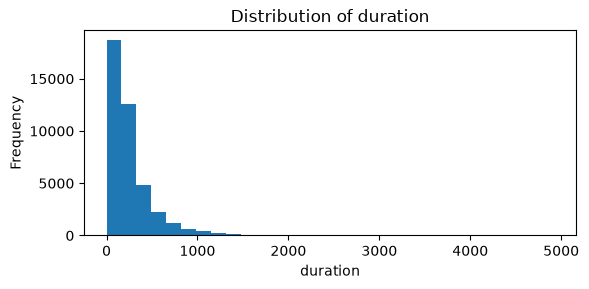

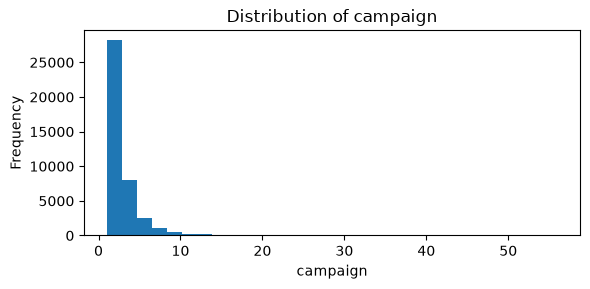

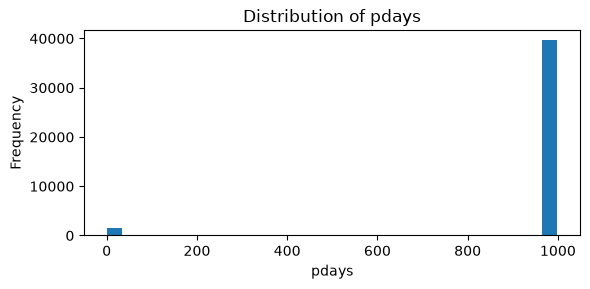

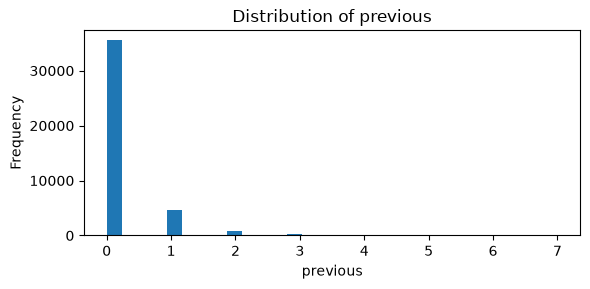

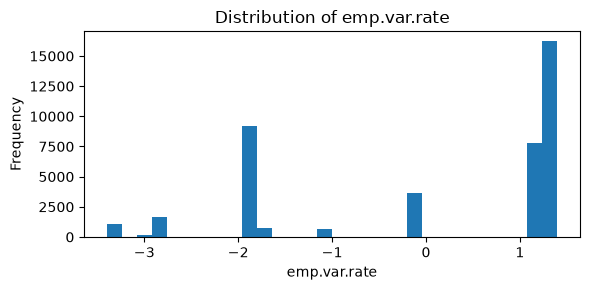

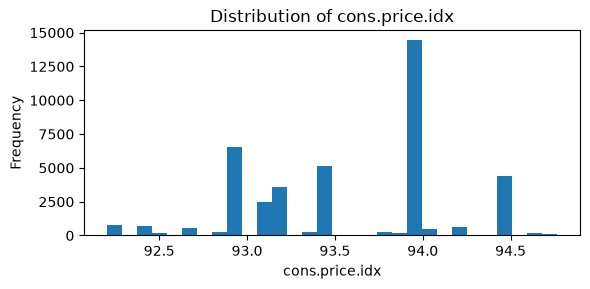

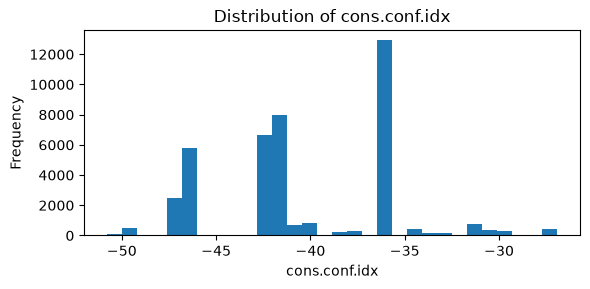

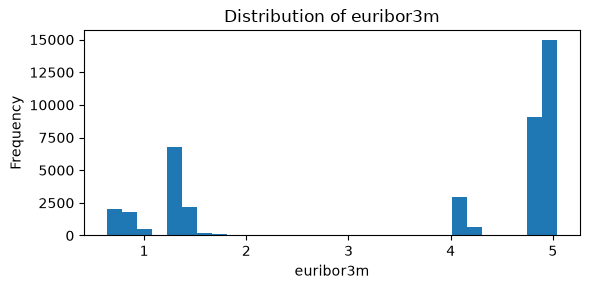

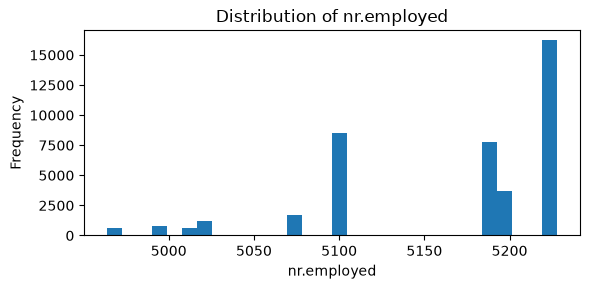

In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].describe().T)

for col in numeric_cols:
    plt.figure(figsize=(6,3))
    plt.hist(df[col].dropna(), bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()



C:\Users\DELL\AppData\Local\Temp\ipykernel_17384\2990922065.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


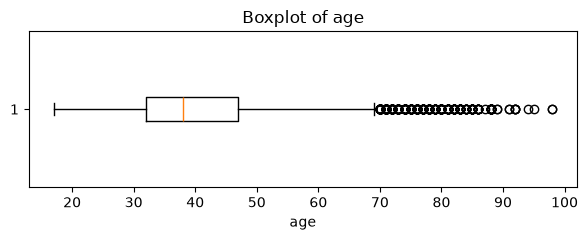

C:\Users\DELL\AppData\Local\Temp\ipykernel_17384\2990922065.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


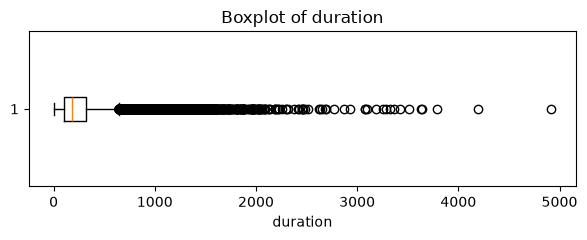

C:\Users\DELL\AppData\Local\Temp\ipykernel_17384\2990922065.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


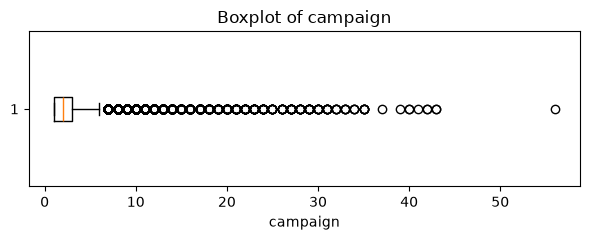

C:\Users\DELL\AppData\Local\Temp\ipykernel_17384\2990922065.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False)


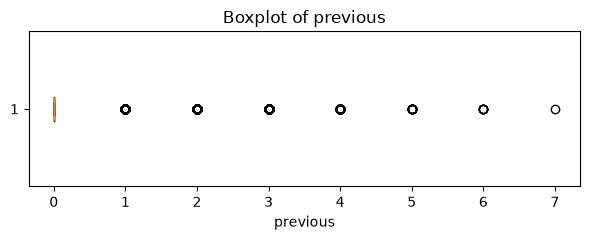

In [7]:
for col in ["age", "duration", "campaign", "previous"]:
    plt.figure(figsize=(6,2.5))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


## 8. Categorical feature analysis

The categorical variables include job, marital status, education, credit default, housing loan, personal loan, contact type, month, day of week, and previous campaign outcome. Frequency tables and charts show how the customer records are distributed across categories.


C:\Users\DELL\AppData\Local\Temp\ipykernel_17384\4240105784.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.drop("y").tolist()


\njob


,count
job,
admin.,10422
blue-collar,9254
technician,6743
services,3969
management,2924
retired,1720
entrepreneur,1456
self-employed,1421
housemaid,1060


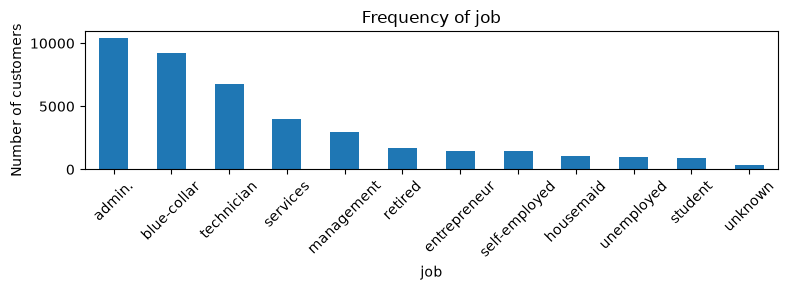

\nmarital


,count
marital,
married,24928
single,11568
divorced,4612
unknown,80


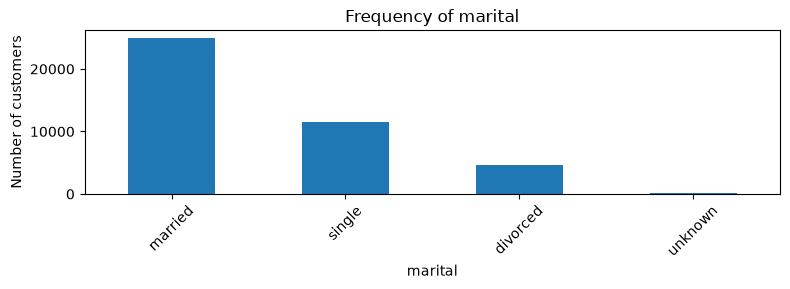

\neducation


,count
education,
university.degree,12168
high.school,9515
basic.9y,6045
professional.course,5243
basic.4y,4176
basic.6y,2292
unknown,1731
illiterate,18


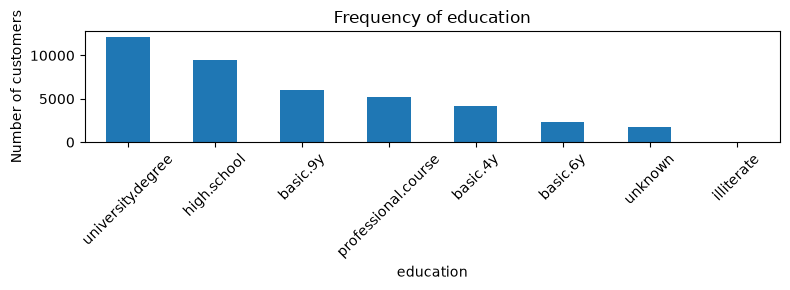

\ndefault


,count
default,
no,32588
unknown,8597
yes,3


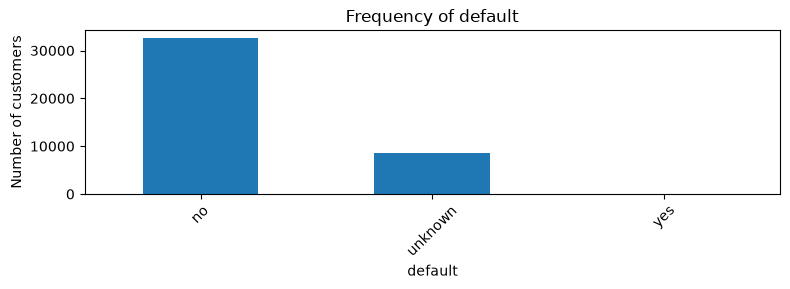

\nhousing


,count
housing,
yes,21576
no,18622
unknown,990


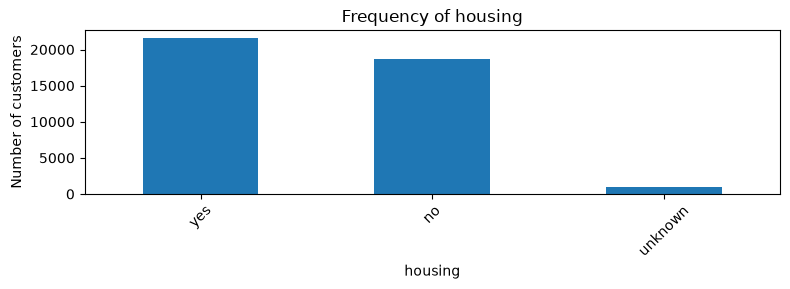

\nloan


,count
loan,
no,33950
yes,6248
unknown,990


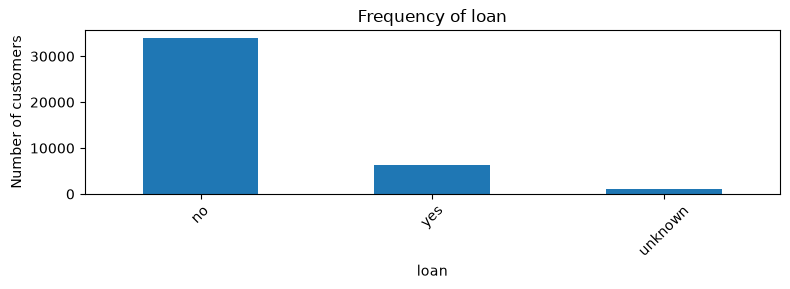

\ncontact


,count
contact,
cellular,26144
telephone,15044


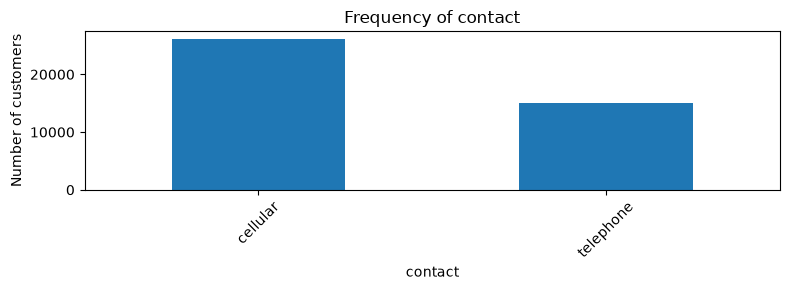

\nmonth


,count
month,
may,13769
jul,7174
aug,6178
jun,5318
nov,4101
apr,2632
oct,718
sep,570
mar,546


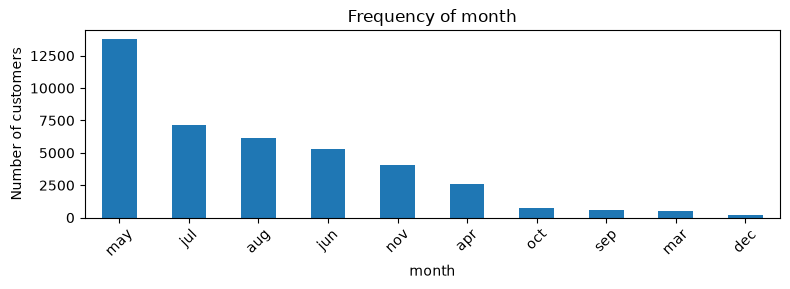

\nday_of_week


,count
day_of_week,
thu,8623
mon,8514
wed,8134
tue,8090
fri,7827


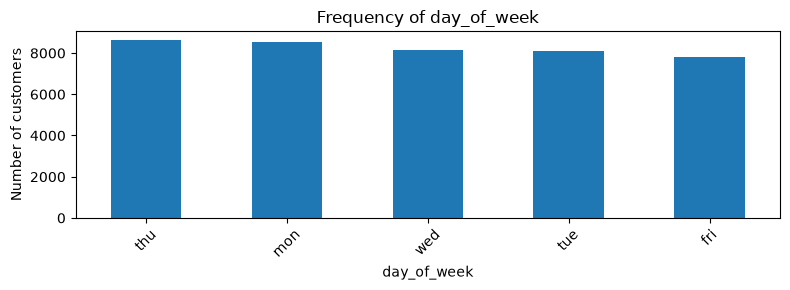

\npoutcome


,count
poutcome,
nonexistent,35563
failure,4252
success,1373


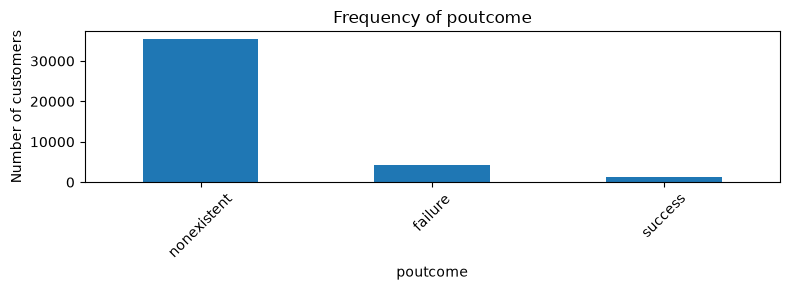

In [8]:
categorical_cols = df.select_dtypes(include="object").columns.drop("y").tolist()

for col in categorical_cols:
    counts = df[col].value_counts(dropna=False)
    print(f"\\n{col}")
    display(counts.to_frame("count"))
    counts.plot(kind="bar", figsize=(8,3), title=f"Frequency of {col}", rot=45)
    plt.ylabel("Number of customers")
    plt.tight_layout()
    plt.show()


## 9. Subscription rate by category

Counts alone do not show which categories have a higher subscription proportion. The following analysis calculates the percentage of `yes` outcomes within each category. These are descriptive associations, not proof that a category causes subscription.


\nSubscription rate by job (%):


,subscription_rate_pct
job,
student,31.43
retired,25.23
unemployed,14.20
admin.,12.97
management,11.22
unknown,11.21
technician,10.83
self-employed,10.49
housemaid,10.00


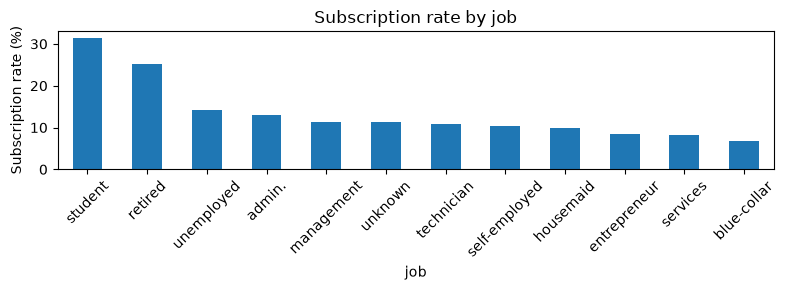

\nSubscription rate by marital (%):


,subscription_rate_pct
marital,
unknown,15.00
single,14.00
divorced,10.32
married,10.16


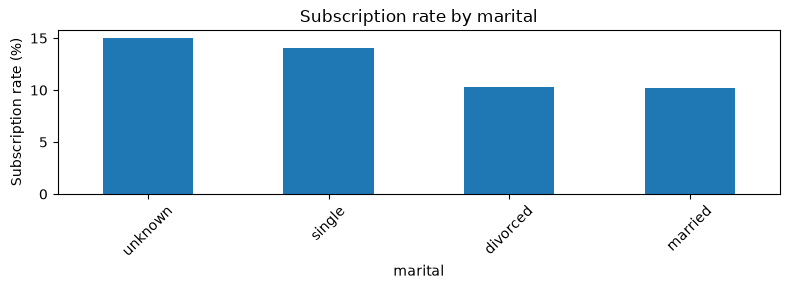

\nSubscription rate by education (%):


,subscription_rate_pct
education,
illiterate,22.22
unknown,14.50
university.degree,13.72
professional.course,11.35
high.school,10.84
basic.4y,10.25
basic.6y,8.20
basic.9y,7.82


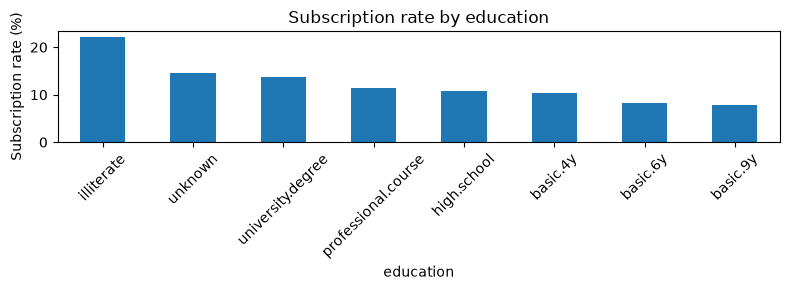

\nSubscription rate by default (%):


,subscription_rate_pct
default,
no,12.88
unknown,5.15
yes,0.00


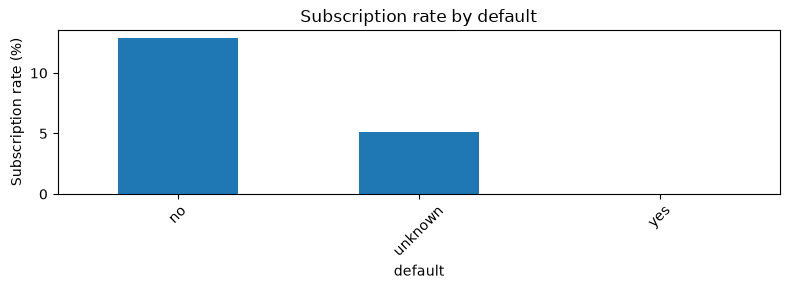

\nSubscription rate by housing (%):


,subscription_rate_pct
housing,
yes,11.62
no,10.88
unknown,10.81


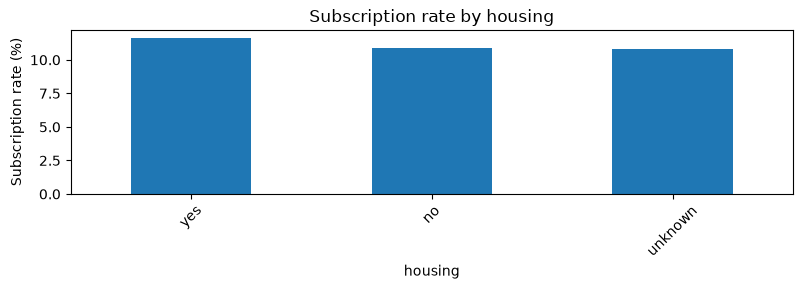

\nSubscription rate by loan (%):


,subscription_rate_pct
loan,
no,11.34
yes,10.93
unknown,10.81


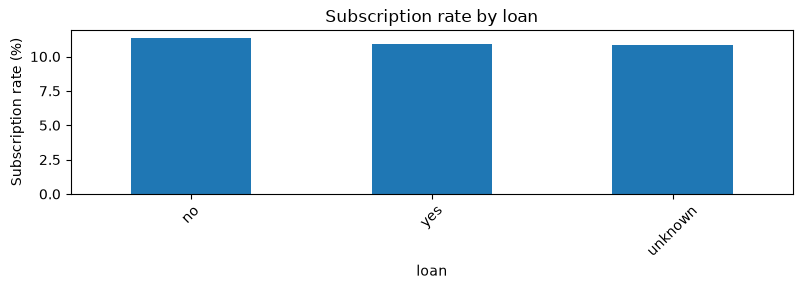

\nSubscription rate by contact (%):


,subscription_rate_pct
contact,
cellular,14.74
telephone,5.23


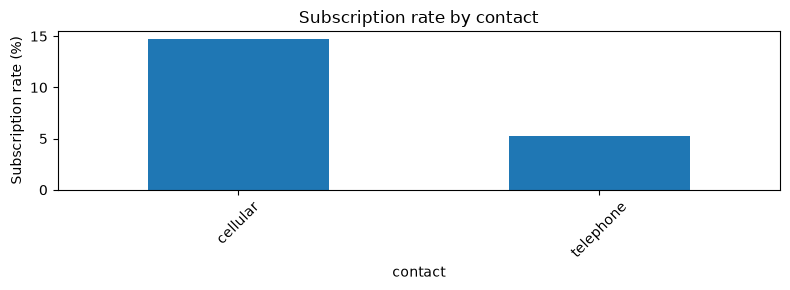

\nSubscription rate by month (%):


,subscription_rate_pct
month,
mar,50.55
dec,48.90
sep,44.91
oct,43.87
apr,20.48
aug,10.60
jun,10.51
nov,10.14
jul,9.05


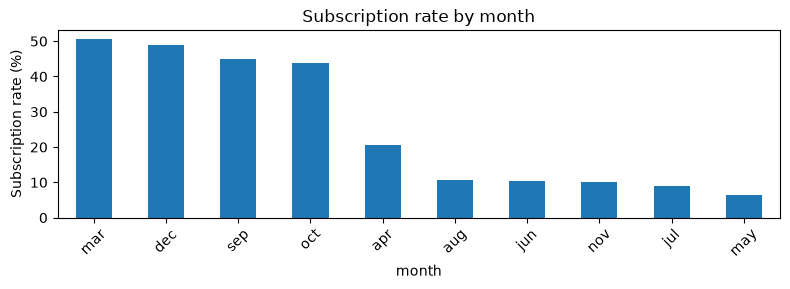

\nSubscription rate by day_of_week (%):


,subscription_rate_pct
day_of_week,
thu,12.12
tue,11.78
wed,11.67
fri,10.81
mon,9.95


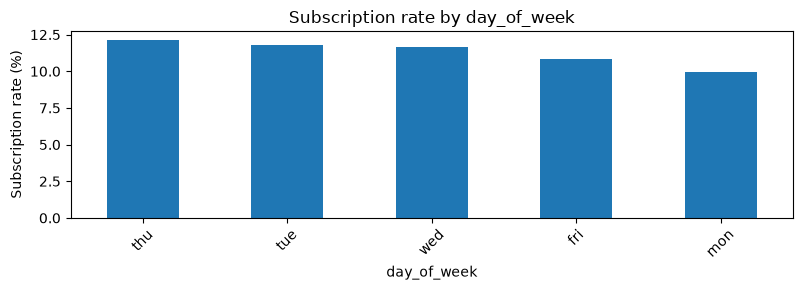

\nSubscription rate by poutcome (%):


,subscription_rate_pct
poutcome,
success,65.11
failure,14.23
nonexistent,8.83


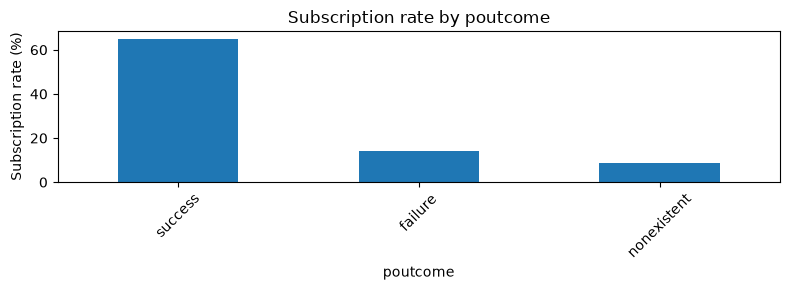

In [9]:
for col in categorical_cols:
    rate = (df.groupby(col, dropna=False)["y"]
              .apply(lambda s: s.eq("yes").mean() * 100)
              .sort_values(ascending=False))
    print(f"\\nSubscription rate by {col} (%):")
    display(rate.round(2).to_frame("subscription_rate_pct"))
    rate.plot(kind="bar", figsize=(8,3), title=f"Subscription rate by {col}", rot=45)
    plt.ylabel("Subscription rate (%)")
    plt.tight_layout()
    plt.show()


## 10. Correlation analysis

Correlation is calculated for numerical columns only. It measures linear association and does not establish causation. Because economic indicators may move together, interpret correlated variables carefully.


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
age,1.00,-0.00,0.00,-0.03,0.02,-0.00,0.00,0.13,0.01,-0.02
duration,-0.00,1.00,-0.07,-0.05,0.02,-0.03,0.01,-0.01,-0.03,-0.04
campaign,0.00,-0.07,1.00,0.05,-0.08,0.15,0.13,-0.01,0.14,0.14
pdays,-0.03,-0.05,0.05,1.00,-0.59,0.27,0.08,-0.09,0.30,0.37
previous,0.02,0.02,-0.08,-0.59,1.00,-0.42,-0.20,-0.05,-0.45,-0.50
emp.var.rate,-0.00,-0.03,0.15,0.27,-0.42,1.00,0.78,0.20,0.97,0.91
cons.price.idx,0.00,0.01,0.13,0.08,-0.20,0.78,1.00,0.06,0.69,0.52
cons.conf.idx,0.13,-0.01,-0.01,-0.09,-0.05,0.20,0.06,1.00,0.28,0.10
euribor3m,0.01,-0.03,0.14,0.30,-0.45,0.97,0.69,0.28,1.00,0.95
nr.employed,-0.02,-0.04,0.14,0.37,-0.50,0.91,0.52,0.10,0.95,1.00


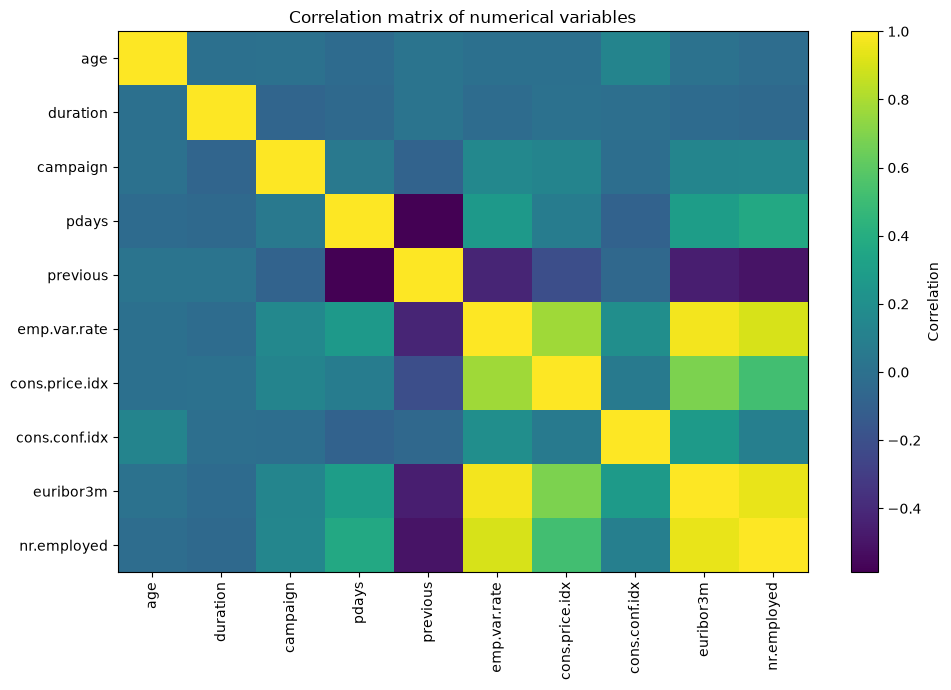

In [10]:
corr = df[numeric_cols].corr(numeric_only=True)
display(corr.round(2))

plt.figure(figsize=(10,7))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation matrix of numerical variables")
plt.tight_layout()
plt.show()


## 11. Campaign and previous-contact analysis

`campaign` records the number of contacts in the current campaign for a customer. `previous` records contacts before the current campaign. `poutcome` records the outcome of the previous campaign. `pdays = 999` means there was no previous contact in the earlier campaign.

Compare the subscription rate across contact-frequency bands and previous campaign outcomes.


In [11]:
df["campaign_group"] = pd.cut(
    df["campaign"],
    bins=[0, 1, 2, 3, 5, 10, np.inf],
    labels=["1", "2", "3", "4-5", "6-10", "11+"]
)
display(pd.crosstab(df["campaign_group"], df["y"], normalize="index").mul(100).round(2))

df["previous_contact_status"] = np.where(df["pdays"].eq(999), "Not previously contacted", "Previously contacted")
display(pd.crosstab(df["previous_contact_status"], df["y"], normalize="index").mul(100).round(2))


y,no,yes
campaign_group,,
1,86.96,13.04
2,88.54,11.46
3,89.25,10.75
4-5,91.32,8.68
6-10,93.68,6.32
11+,96.89,3.11


y,no,yes
previous_contact_status,,
Not previously contacted,90.74,9.26
Previously contacted,36.17,63.83


## 12. Key findings from the supplied dataset

The following figures are calculated from the provided CSV and can be rechecked by running the notebook:

- **Dataset size:** 41,188 customer records and 21 original columns.
- **Target distribution:** 36,548 `no` records and 4,640 `yes` records.
- **Overall subscription rate:** approximately 11.27%; the target is imbalanced.
- **Null values:** check the output in Section 4; the supplied data represents several unavailable categorical values using `unknown`.
- **Age:** mean age is approximately 40 years; median age is 38 years.
- **Campaign contacts:** the median number of contacts in the current campaign is 2.
- **Previous contact:** `pdays = 999` is the dominant value and means the customer was not previously contacted.
- **Contact type:** in this dataset, the descriptive subscription rate is higher for cellular contacts than telephone contacts.
- **Previous campaign outcome:** customers whose previous campaign outcome was `success` have a much higher observed subscription rate than the other outcome groups.
- **Month:** observed subscription rates differ substantially by month; month-level results should be interpreted with campaign timing and sample sizes in mind.

These are associations in historical campaign data. They do not guarantee that the same outcomes will occur in a future campaign.


## 13. Business recommendations based on Task 1 EDA

1. Review the historical segments with higher observed subscription rates, particularly customers with a successful previous campaign outcome.
2. Compare contact channels using both subscription rate and the number of customers contacted; the cellular segment has a higher observed rate in this dataset.
3. Plan campaign timing using month-level performance, while checking the number of records in each month so that small groups are not over-interpreted.
4. Monitor repeated contacts. Examine outcomes by `campaign` count and avoid assuming that more calls automatically improve conversion.
5. Treat `unknown` values explicitly. Consider whether they represent unavailable customer information and whether a separate category is appropriate for later modelling.
6. Use the economic indicators to understand the campaign context, but check their relationships and possible time effects before using them in a model.
7. Do not use `duration` as an input to a realistic pre-call prediction model. It is only known after the call and can cause target leakage.
8. Evaluate future campaigns with a holdout set and business-focused measures such as precision, recall, lift, and the number of successful subscriptions—not accuracy alone.


## 14. Conclusion

The Portuguese bank marketing dataset contains 41,188 records describing customers and direct marketing campaign activity. Only about 11.27% of customers in the supplied data subscribed to a term deposit, so the target class is imbalanced. The EDA highlights differences in observed subscription rates across contact type, month, job group, and previous campaign outcome. These patterns can help the bank form hypotheses for campaign planning.

Task 1 is descriptive analysis. The next project task should build and compare predictive models using a realistic feature set, excluding `duration` as instructed in the project brief. All findings should be validated on unseen data before operational use.


## 15. Dataset reference

Project brief: `PRCP-1000-PortugeseBank`. Dataset: `Data/bank-additional/bank-additional-full.csv`, from the supplied `PRCP-1000-ProtugeseBank.zip` archive. Target variable: `y` (yes/no).


### 2. Loading the Dataset

In [12]:
import pandas as pd

csv_path = r"C:\Users\DELL\Desktop\Portuguese_Bank_Project\PRCP-1000-ProtugeseBank\Data\bank-additional\bank-additional-full.csv"

df = pd.read_csv(csv_path, sep=";")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 3. Data Cleaning and Preprocessing

In This step, we check the dataset for missing values, duplicate records, and unknown
values. We clean the data to prepare it for machine learning models.

In [13]:
# Check dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check unknown values
print("\nUnknown Values:")
print((df == "unknown").sum())

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

### 4. Removing Duplicate Records

In this step, duplicate records are removed from the dataset to avoid
repeated information and improve data quality.

In [14]:
# Check duplicates before removal
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Check dataset after removal
print("Duplicates after cleaning:", df.duplicated().sum())
print("Updated Dataset Shape:", df.shape)

Duplicates before cleaning: 12
Duplicates after cleaning: 0
Updated Dataset Shape: (41176, 21)


### 5. Separating Features and Target Variable

In this step, we separate the independent variables (features) and dependent variable (target).
    The target variable is 'y', which indicates whether a customer subscribed to a term deposit.

In [15]:
# Separate input features and target variable

X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (41176, 19)
Target Shape: (41176,)

Target Distribution:
y
0    36537
1     4639
Name: count, dtype: int64


### 6. Splitting Data into Training and Testing Sets

In this step, the dataset is divided into training and testing sets. 
    The training set is used to train the machine learning models,
while the testing set is used to evaluate their performance.

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (32940, 19)
Testing Data Shape: (8236, 19)
Training Target Shape: (32940,)
Testing Target Shape: (8236,)


### 7. Data Preprocessing

In [18]:
# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(include=np.number).columns
categorical_features = X_train.select_dtypes(exclude=np.number).columns

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

Numerical Features: 9
Categorical Features: 10


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

print("Libraries imported successfully!")

Libraries imported successfully!


In [20]:
# Preprocessing for numerical data

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical data

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


### 8. Building Machine Learning Models

In [21]:
We will train three machine learning algorithms to predict whether a customer will subscribe to a term deposit."
- Logistic Regression
- Decision Tree
- Random Forest

SyntaxError: unterminated string literal (detected at line 1) (364930207.py, line 1)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("All ML models imported successfully!")

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

print("Three Machine Learning Models Created Successfully!")

### 9. Training and Evaluating Models

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("Evaluation metrics imported successfully!")

In [ ]:
results = []
trained_models = {}

for name, model in models.items():

    # Create a machine learning pipeline
    clf = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train the model
    clf.fit(X_train, y_train)

    # Make predictions
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    # Evaluate performance
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

    trained_models[name] = clf

print("All models trained successfully!")

### 10. Model Performance Comparison

In [ ]:
# Convert results into a DataFrame

results_df = pd.DataFrame(results)

# Display model comparison
results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
)

results_df

### 11. Model Performance Visualization

In [ ]:
# Compare model performance using a bar chart

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

### 12. Confusion Matrix of Machine Learning Models

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("Confusion Matrix imported successfully!")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, clf) in zip(axes, trained_models.items()):

    y_pred = clf.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()

### 13. ROC Curve Comparison

In [ ]:
from sklearn.metrics import RocCurveDisplay

print("RocCurveDisplay imported successfully!")

In [ ]:
plt.figure(figsize=(9, 6))

for name, clf in trained_models.items():
    y_prob = clf.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Select the model with the highest PR-AUC score

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best PR-AUC Score:", results_df.iloc[0]["PR-AUC"])

### 14. Best Model Selection

In [ ]:
# Select the model with the highest PR-AUC score

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best PR-AUC Score:", results_df.iloc[0]["PR-AUC"])

HOW MANY ### 15. Classification Report of the Best Model

In [ ]:
# Generate predictions using the best model
from sklearn.metrics import classification_report

y_pred_best = best_model.predict(X_test)

# Display classification report

print("Best Model:", best_model_name)
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_best,
    target_names=["No", "Yes"]
))

In [ ]:
from sklearn.metrics import classification_report

print("Classification report imported successfully!")

### 16. Challenges Faced During Predictive Modelling


1. Imbalanced Dataset: The number of customers who subscribed was much lower than those who did not.

2. Missing and Unknown Values: Some categorical columns contained unknown values.

3. Data Preprocessing: Numerical and categorical data required different preprocessing techniques.

4. Feature Selection: The duration column was excluded because it is known only after the phone call.

5. Model Selection: Three machine learning algorithms were tested.

6. Model Evaluation: Multiple evaluation metrics were used to compare model performance.

Conclusion

In this project, three machine learning algorithms—Logistic Regression, Decision Tree and Random Forest—were developed to predict whether a customer would subscribe to a bank term deposit.

The models were evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.

The best-performing model was selected based on the PR-AUC score. This predictive model can help the bank identify potential customers and improve its marketing campaigns.

The project demonstrates how machine learning can support data-driven decision-making in banking.

## Task 3 – Business Recommendations

In [ ]:
# Analyze customer subscription

subscription_count = df["y"].value_counts()

print("Customer Subscription Details:")
print(subscription_count)

subscription_percentage = df["y"].value_counts(normalize=True) * 100

print("\nSubscription Percentage:")
print(subscription_percentage)

### 2. Customer Age Group Analysis

In [ ]:
# Create age groups

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["Below 25", "26-35", "36-45", "46-55", "56-65", "Above 65"]
)

# Calculate subscription percentage by age group

age_analysis = df.groupby("age_group", observed=False)["y"].value_counts(
    normalize=True
).unstack(fill_value=0) * 100

print("Age Group Subscription Analysis:")
print(age_analysis)

### 3. Job-wise Subscription Analysis

In [ ]:
# Analyze subscription based on job type

job_analysis = df.groupby("job")["y"].value_counts(
    normalize=True
).unstack(fill_value=0) * 100

print("Job-wise Subscription Analysis:")
print(job_analysis.sort_values(by="yes", ascending=False))

### 4. Education and Marital Status Analysis

In [ ]:


education_analysis = df.groupby("education")["y"].value_counts(
    normalize=True
).unstack(fill_value=0) * 100

print("Education-wise Subscription Analysis:")
print(education_analysis.sort_values(by="yes", ascending=False))


# Marital status-wise subscription analysis

marital_analysis = df.groupby("marital")["y"].value_counts(
    normalize=True
).unstack(fill_value=0) * 100

print("\nMarital Status-wise Subscription Analysis:")
print(marital_analysis.sort_values(by="yes", ascending=False))

### 5. Identifying Potential Customers

In [ ]:
# Predict subscription probabilities

customer_probabilities = best_model.predict_proba(X)[:, 1]

# Create a customer analysis dataframe

potential_customers = df.copy()

potential_customers["subscription_probability"] = customer_probabilities

# Display customers with highest subscription probability

potential_customers = potential_customers.sort_values(
    by="subscription_probability",
    ascending=False
)

print("Top 10 Potential Customers:")
display(
    potential_customers[
        ["age", "job", "marital", "education", "subscription_probability"]
    ].head(10)
)

### 6. Business Recommendations

Based on the data analysis and predictive modelling, the following recommendations are suggested for the Portuguese Bank:

1. Target Potential Customers:Use the machine learning model to identify customers who are more likely to subscribe to term deposits.

2. Age-Based Marketing:Design suitable marketing campaigns for different customer age groups.

3.Job-Based Marketing:Focus on job categories showing higher subscription percentages.

4. Personalized Campaigns:Consider customers' education and marital status when planning marketing strategies.

5.Improve Customer Communication:Train marketing staff to communicate the benefits of term deposits clearly.

6.Use Data-Driven Decisions:
    Regularly analyze customer data and update predictive models to improve campaign performance.

7.Monitor Campaign Results:Track subscription rates and customer responses to improve future marketing campaigns.

### 7. Final Conclusion

### Final Conclusion

The Portuguese Bank Marketing project involved data analysis, predictive modelling and business recommendations.

In Task 1, exploratory data analysis was performed to understand customer information and subscription patterns.

In Task 2, three machine learning algorithms—Logistic Regression, Decision Tree and Random Forest—were developed and compared to predict customer subscriptions.

In Task 3, customer groups were analyzed and business recommendations were provided to improve marketing strategies.

Overall, this project demonstrates how data science and machine learning can help banks understand customers, identify potential subscribers and make better business decisions.

## Model Comparison Report

In this project, three machine learning models were implemented to predict whether a customer will subscribe to a term deposit: Logistic Regression, Decision Tree, and Random Forest.

The performance of these models was evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, and PR-AUC.

- **Logistic Regression:** Used as a baseline model to understand the relationship between customer features and subscription probability.
- **Decision Tree:** Used to identify customer patterns through decision rules. It is easy to understand but may overfit the training data.
- **Random Forest:** Uses multiple decision trees to improve prediction performance and reduce overfitting.

Since the dataset is imbalanced, PR-AUC was considered an important metric for comparing the models. The model with the highest PR-AUC was selected as the best candidate.

The selected model can help the bank identify potential customers who are more likely to subscribe to a term deposit. However, before production deployment, the model should be further evaluated using recent data and business requirements.

**Conclusion:** Model comparison helps identify the most suitable machine learning model for predicting customer subscriptions and improving the efficiency of bank marketing campaigns.

In [ ]:
print("MODEL COMPARISON REPORT")
print("=" * 50)

display(results_df.round(4))

print("\nBest Model:", best_model_name)
print("Selection Metric: PR-AUC")
print("Best PR-AUC Score:", round(results_df.iloc[0]["PR-AUC"], 4))

## Report on Challenges Faced

During the Portuguese Bank Marketing Prediction project, several challenges were encountered while analysing the dataset and building machine learning models.

### 1. Imbalanced Dataset
The number of customers who subscribed to a term deposit was much lower than the number who did not subscribe.

**Technique Used:** Class distribution analysis and evaluation using Precision, Recall, F1-score and PR-AUC.

**Reason:** These metrics help evaluate model performance when the target classes are imbalanced.

### 2. Data Preprocessing
The dataset contained both numerical and categorical features.

**Technique Used:** Separate preprocessing techniques were applied to numerical and categorical columns.

**Reason:** Different data types require different preprocessing methods before model training.

### 3. Missing and Unknown Values
Some categorical columns contained unknown values.

**Technique Used:** Unknown values were identified and handled during data preprocessing.

**Reason:** Proper handling of unknown values helps maintain data quality.

### 4. Model Selection
Choosing the best machine learning model was challenging because different models produced different performance results.

**Technique Used:** Logistic Regression, Decision Tree and Random Forest were trained and compared using multiple evaluation metrics.

**Reason:** Comparing models helps identify the most suitable model for the prediction task.

### 5. Model Performance Evaluation
Accuracy alone was not sufficient to evaluate the models because the dataset was imbalanced.

**Technique Used:** PR-AUC was given importance while comparing model performance.

**Reason:** PR-AUC helps evaluate the balance between precision and recall for the positive class.

### Conclusion
The project helped in understanding real-world data preprocessing, handling imbalanced datasets, training machine learning models and evaluating their performance. Random Forest achieved the highest PR-AUC score of 0.4875 and was selected as the best candidate among the three models.